In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns

from src import RESULTS_DIR

# -----------------------------
# Publication-quality settings
# -----------------------------
plt.rcParams.update(
    {
        "text.usetex": True,
        "font.family": "serif",
        "font.size": 10,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "figure.figsize": (6.5, 4.5),
        "figure.dpi": 100,
        "savefig.dpi": 300,
        "lines.linewidth": 2.0,
        "lines.markersize": 5,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "axes.axisbelow": True,
        "legend.frameon": False,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

sns.set_palette("deep")

## MPI Static vs Dynamic Plots

In [15]:
base_dir = Path("/home/prajwal/github-repos/hatann/tacc-files/st-v-dy")
npz_files = list(base_dir.glob("*.npz"))

static_npz = [j for j in npz_files if "stealFalse" in j.name][0]
dynamic_npz = [j for j in npz_files if "stealTrue" in j.name][0]
print(f"Found static npz: {static_npz}")
print(f"Found dynamic npz: {dynamic_npz}")
static_data = np.load(static_npz, allow_pickle=True)
dynamic_data = np.load(dynamic_npz, allow_pickle=True)

# convert to dict
static_data_dict = {k: static_data[k] for k in static_data.files}
dynamic_data_dict = {k: dynamic_data[k] for k in dynamic_data.files}

Found static npz: /home/prajwal/github-repos/hatann/tacc-files/st-v-dy/mpi_sz16_rosen100.0_ntrain1000000_dim5_tol0.05_erraffine_cov_hess_metricLinf-local_inituniform_grid_nclust92_minpts371_stealFalse.npz
Found dynamic npz: /home/prajwal/github-repos/hatann/tacc-files/st-v-dy/mpi_sz16_rosen100.0_ntrain1000000_dim5_tol0.05_erraffine_cov_hess_metricLinf-local_inituniform_grid_nclust92_minpts371_stealTrue.npz


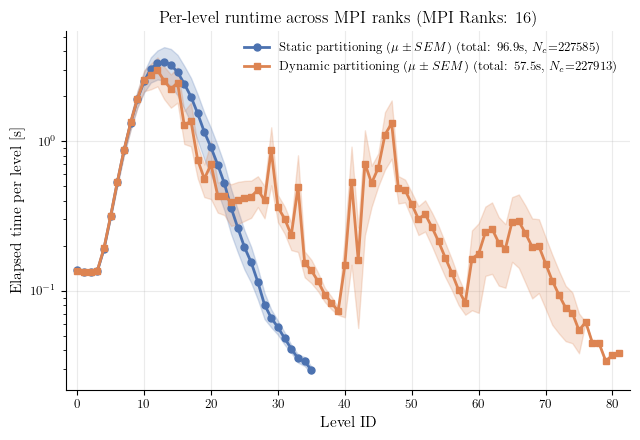

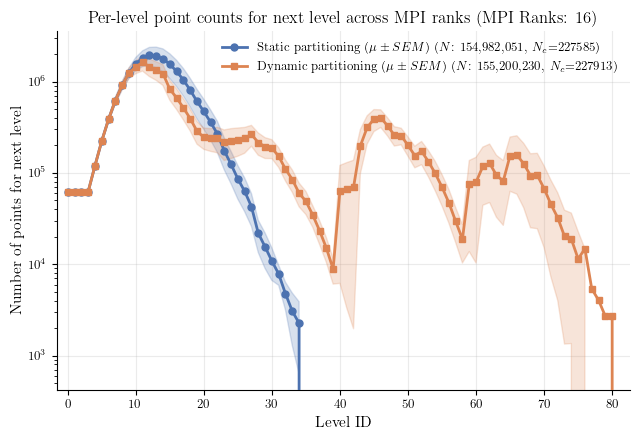

In [16]:
# ----------------------------------------------------------
# Helper: convert list-of-dicts level_stats -> summary by level
# ----------------------------------------------------------
def summarize_level_stats(level_stats, metric="runtime_sec"):
    """
    Parameters
    ----------
    level_stats : list[dict]
        Each dict corresponds to one rank at one level.
    metric : str
        Field to aggregate across ranks at each level.
        Examples:
            - "runtime_sec"
            - "size_mean"
            - "num_pts_next_level"
            - "good_clusters"
            - "clusters_level_end"

    Returns
    -------
    summary_df : pd.DataFrame
        Columns: level, mean, std, min, max, count
    raw_df : pd.DataFrame
        Raw per-rank dataframe
    """
    df = pd.DataFrame(level_stats).copy()

    if metric not in df.columns:
        raise ValueError(
            f"Metric '{metric}' not found. Available columns:\n{list(df.columns)}"
        )

    # Ensure numeric + sorted
    df[metric] = pd.to_numeric(df[metric], errors="coerce")
    df["level"] = pd.to_numeric(df["level"], errors="coerce")

    summary = (
        df.groupby("level")[metric]
        .agg(["mean", "std", "min", "max", "count"])
        .reset_index()
        .sort_values("level")
    )

    # If a level has only one rank entry, std will be NaN -> set to 0
    summary["std"] = summary["std"].fillna(0.0)

    return summary, df


# ----------------------------------------------------------
# Main plotting function
# ----------------------------------------------------------
def plot_level_comparison(
    static_level_stats,
    dynamic_level_stats,
    metric="runtime_sec",
    metric_label=None,
    title=None,
    savepath=None,
    show_rank_scatter=False,
    use_sem=False,
    extra_static_label="",
    extra_dynamic_label="",
    skip_x=2,
    y_log_scale=False,
):
    """
    Plot mean +/- std (or SEM) across MPI ranks per level for static vs dynamic.

    Parameters
    ----------
    static_level_stats, dynamic_level_stats : list[dict]
        level_stats from the two experiments
    metric : str
        Metric to plot
    metric_label : str or None
        y-axis label
    title : str or None
        optional title
    savepath : str or None
        if given, saves figure
    show_rank_scatter : bool
        overlay faint per-rank points
    use_sem : bool
        if True, shaded band = standard error instead of standard deviation
    """
    static_summary, static_raw = summarize_level_stats(
        static_level_stats, metric=metric
    )
    dynamic_summary, dynamic_raw = summarize_level_stats(
        dynamic_level_stats, metric=metric
    )
    num_ranks = static_raw["rank"].nunique()

    # Union of levels so both curves align even if one stops earlier
    all_levels = np.union1d(
        static_summary["level"].to_numpy(), dynamic_summary["level"].to_numpy()
    )

    static_summary = (
        static_summary.set_index("level")
        .reindex(all_levels)
        .reset_index()
        .rename(columns={"index": "level"})
    )
    dynamic_summary = (
        dynamic_summary.set_index("level")
        .reindex(all_levels)
        .reset_index()
        .rename(columns={"index": "level"})
    )

    # Convert std -> sem if requested
    if use_sem:
        static_band = static_summary["std"] / np.sqrt(static_summary["count"])
        dynamic_band = dynamic_summary["std"] / np.sqrt(dynamic_summary["count"])
        band_label = "SEM"
    else:
        static_band = static_summary["std"]
        dynamic_band = dynamic_summary["std"]
        band_label = "Std. Dev."

    fig, ax = plt.subplots()

    colors = sns.color_palette("deep", 2)
    c_static = colors[0]
    c_dynamic = colors[1]

    # Optional faint per-rank points
    if show_rank_scatter:
        ax.scatter(
            static_raw["level"],
            static_raw[metric],
            color=c_static,
            alpha=0.25,
            s=18,
            zorder=1,
            label=None,
        )
        ax.scatter(
            dynamic_raw["level"],
            dynamic_raw[metric],
            color=c_dynamic,
            alpha=0.25,
            s=18,
            zorder=1,
            label=None,
        )

    # Static mean and band
    ax.plot(
        static_summary["level"],
        static_summary["mean"],
        marker="o",
        color=c_static,
        label=rf"Static partitioning ($\mu \pm {band_label}$){extra_static_label}",
        zorder=3,
    )
    ax.fill_between(
        static_summary["level"],
        static_summary["mean"] - static_band,
        static_summary["mean"] + static_band,
        color=c_static,
        alpha=0.22,
        zorder=2,
    )

    # Dynamic mean and band
    ax.plot(
        dynamic_summary["level"],
        dynamic_summary["mean"],
        marker="s",
        color=c_dynamic,
        label=rf"Dynamic partitioning ($\mu \pm {band_label}$){extra_dynamic_label}",
        zorder=3,
    )
    ax.fill_between(
        dynamic_summary["level"],
        dynamic_summary["mean"] - dynamic_band,
        dynamic_summary["mean"] + dynamic_band,
        color=c_dynamic,
        alpha=0.22,
        zorder=2,
    )
    if y_log_scale:
        ax.set_yscale("log")

    # Labels
    if metric_label is None:
        metric_label = metric.replace("_", r"\_")

    ax.set_xlabel(r"Level ID")
    ax.set_ylabel(metric_label)

    if title is not None:
        ax.set_title(f"{title} (MPI Ranks: {num_ranks})")

    # Set x-ticks at 2-increments and add small margins
    ax.set_xticks(all_levels[::skip_x])
    ax.margins(x=0.02)

    # Better legend placement
    ax.legend(loc="best")

    # Slightly cleaner layout
    fig.tight_layout()

    if savepath is not None:
        fig.savefig(savepath, bbox_inches="tight")

    return fig, ax


# ==========================================================
# Example usage with your loaded data
# ==========================================================
static_level_stats = static_data_dict["profiling_stats"].item()["level_stats"]
dynamic_level_stats = dynamic_data_dict["profiling_stats"].item()["level_stats"]

# Example 1: elapsed time per level across ranks
s_rt = static_data_dict["profiling_stats"].item()["time_total"]
d_rt = dynamic_data_dict["profiling_stats"].item()["time_total"]

s_nc = static_data_dict["profiling_stats"].item()["num_final_clusters"]
d_nc = dynamic_data_dict["profiling_stats"].item()["num_final_clusters"]

skip_x = 10
show_rank_scatter = False
use_sem = True
y_log_scale = True

fig, ax = plot_level_comparison(
    static_level_stats,
    dynamic_level_stats,
    metric="runtime_sec",
    metric_label=r"Elapsed time per level [s]",
    title=r"Per-level runtime across MPI ranks",
    # savepath="level_runtime_comparison.pdf",
    extra_static_label=f" (total: {s_rt:.1f}s, $N_c$={s_nc})",
    extra_dynamic_label=f" (total: {d_rt:.1f}s, $N_c$={d_nc})",
    show_rank_scatter=show_rank_scatter,
    use_sem=use_sem,
    skip_x=skip_x,
    y_log_scale=y_log_scale,
)
plt.show()

s_te = static_data_dict["total_f_evals"]
d_te = dynamic_data_dict["total_f_evals"]
fig, ax = plot_level_comparison(
    static_level_stats,
    dynamic_level_stats,
    metric="num_pts_next_level",
    metric_label=r"Number of points for next level",
    title=r"Per-level point counts for next level across MPI ranks",
    # savepath="level_point_count_comparison.pdf",
    extra_static_label=f" ($N$: {s_te:,}, $N_c$={s_nc})",
    extra_dynamic_label=f" ($N$: {d_te:,}, $N_c$={d_nc})",
    show_rank_scatter=show_rank_scatter,
    use_sem=use_sem,
    skip_x=skip_x,
    y_log_scale=y_log_scale,
)
plt.show()

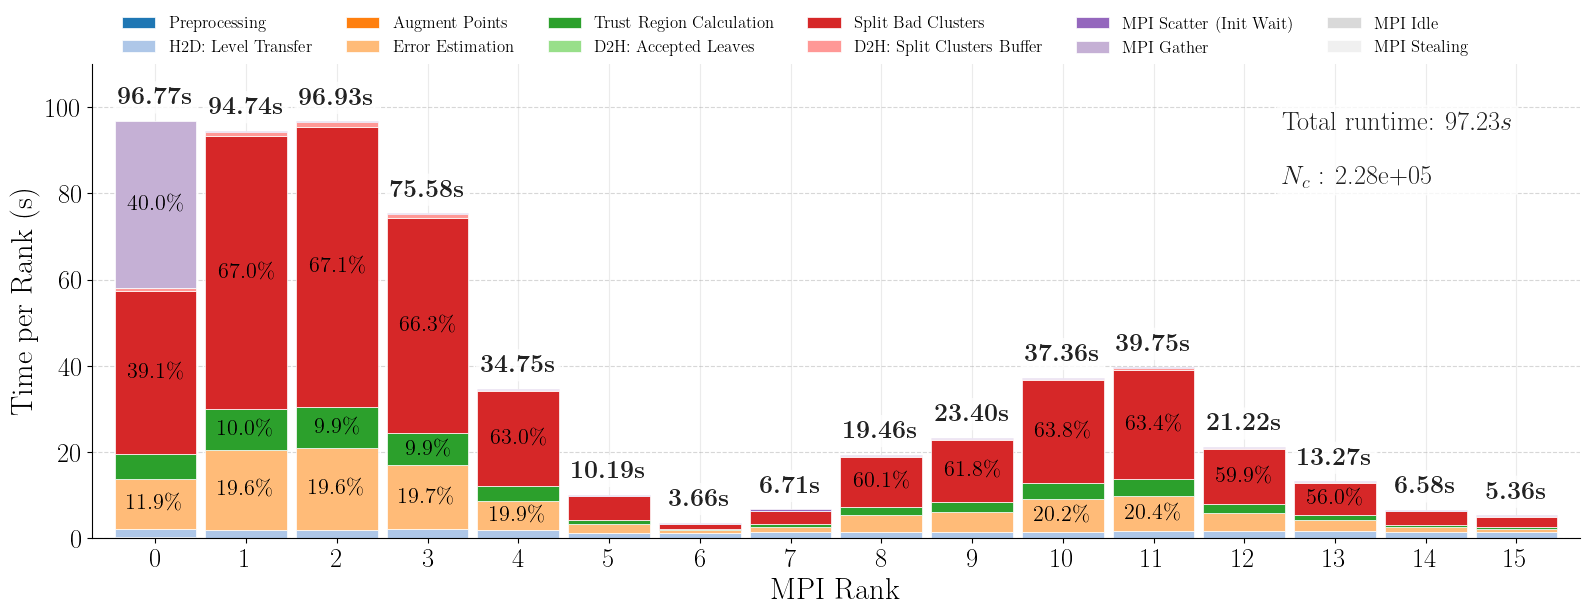

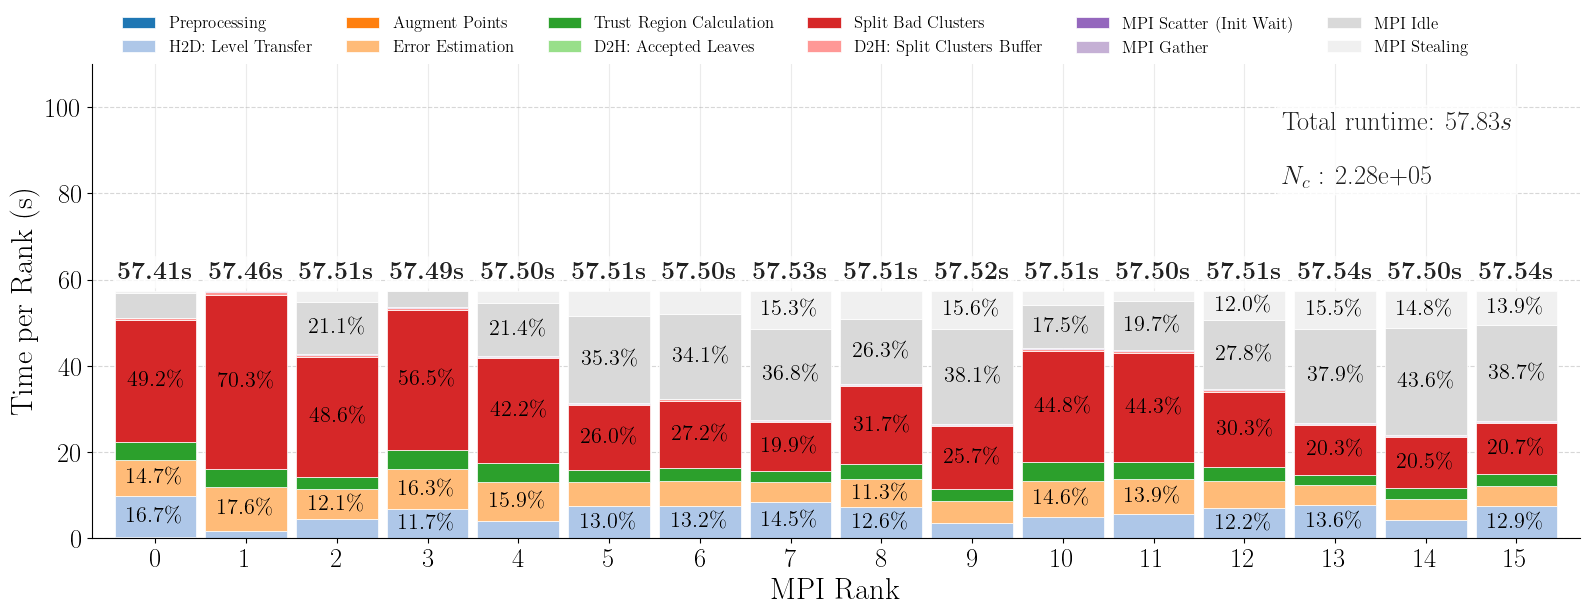

In [25]:
def plot_mpi_rank_time_breakdown_top_only(
    profiling_stats,
    img_fpath: Path,
    top_n_annotate=10,
    annotate_top_n=None,
    min_val_annotate=0.05,
    min_abs_seconds_annotate=1.0,
    figsize=(16, 6),
    tick_fontsize=13,
    axis_title_fontsize=14,
    runtime_label_fontsize=12,
    annotation_fontsize=11,
    ylim=None,
    top_ylim=None,
    runtime_label_pad_frac=0.03,
    x_tick_rotation=0,
):
    """
    Plot only the top stacked runtime bars per MPI rank (absolute seconds, not 100% scaled).

    Args:
        profiling_stats: Dict containing "per_rank" list of dicts with timing info.
        img_fpath: Path to save the resulting figure.
        top_n_annotate: Number of top segments (by within-rank proportion) to annotate.
        annotate_top_n: Alias for top_n_annotate.
        min_val_annotate: Minimum within-rank proportion threshold for segment annotation.
        min_abs_seconds_annotate: Minimum absolute segment height in seconds for annotation.
        figsize: Figure size.
        tick_fontsize: Font size for tick labels.
        axis_title_fontsize: Font size for axis titles.
        runtime_label_fontsize: Font size of total runtime labels above bars.
        annotation_fontsize: Font size for percent annotations.
        ylim: Optional y-limits for top plot.
        top_ylim: Backward-compatible alias for ylim.
        runtime_label_pad_frac: Fraction of max total time used as vertical text padding.
        x_tick_rotation: Rotation angle for x tick labels (0 = horizontal).
    """
    rename_props = {
        "Preprocessing": ["time_init"],
        "H2D: Level Transfer": ["time_transition", "time_slicing", "time_gc"],
        "Augment Points": ["time_find_req_synth", "time_synth_gen"],
        "Error Estimation": ["time_error_calc", "time_filter"],
        "Trust Region Calculation": ["time_good_Q"],
        "D2H: Accepted Leaves": ["time_good_d2h"],
        "Split Bad Clusters": ["time_bad_split"],
        "D2H: Split Clusters Buffer": ["time_bad_d2h"],
        "MPI Scatter (Init Wait)": ["time_scatter"],
        "MPI Gather": ["time_gather"],
        "MPI Idle": ["time_idle"],
        "MPI Stealing": ["time_state_update", "time_mpi_send", "time_mpi_recv"],
    }

    num_ranks = len(profiling_stats["per_rank"])

    rows = []
    for rank in range(num_ranks):
        rank_data = profiling_stats["per_rank"][rank]
        row = {"MPI Rank": rank}
        for category, props in rename_props.items():
            row[category] = sum(rank_data.get(p, 0.0) for p in props)
        row["Total Time (s)"] = rank_data.get("time_total", 0.0)
        rows.append(row)

    rank_df = pd.DataFrame(rows)

    bar_cols = list(rename_props.keys())
    plot_df = rank_df.set_index("MPI Rank")[bar_cols]
    row_sums = plot_df.sum(axis=1)
    plot_df_frac = plot_df.div(row_sums.replace(0.0, np.nan), axis=0).fillna(0.0)

    colors = list(sns.color_palette("tab20", n_colors=len(bar_cols)))
    if len(colors) >= 12:
        colors[10] = (0.85, 0.85, 0.85)  # 11th bar: lighter gray
        colors[11] = (0.94, 0.94, 0.94)  # 12th bar: very light gray

    fig, ax_bar = plt.subplots(figsize=figsize)
    plot_df.plot(
        kind="bar",
        stacked=True,
        ax=ax_bar,
        color=colors,
        width=0.9,
        edgecolor="white",
        linewidth=0.5,
        legend=False,
    )

    y_total = rank_df["Total Time (s)"].to_numpy()
    y_stack_total = row_sums.to_numpy()
    runtime_label_values = y_total.copy()
    if len(runtime_label_values) > 0:
        # Rank 0 profiling total is under-reported; use stacked bar sum for label.
        runtime_label_values[0] = y_stack_total[0]

    max_total = float(np.max(y_stack_total)) if len(y_stack_total) > 0 else 0.0
    y_pad = max(max_total * runtime_label_pad_frac, 0.2)

    effective_ylim = ylim if ylim is not None else top_ylim
    if effective_ylim is None:
        effective_ylim = (0, max_total + 3.5 * y_pad)
    ax_bar.set_ylim(effective_ylim)

    # Segment-level annotations with overlap avoidance per rank.
    top_n_effective = annotate_top_n if annotate_top_n is not None else top_n_annotate
    data_per_pixel = (ax_bar.get_ylim()[1] - ax_bar.get_ylim()[0]) / ax_bar.bbox.height
    label_height_data = annotation_fontsize * fig.dpi / 72.0 * 1.15 * data_per_pixel

    labels_by_rank = {rank: [] for rank in range(num_ranks)}
    for col_idx, container in enumerate(ax_bar.containers):
        for row_idx, patch in enumerate(container):
            pct_val = float(plot_df_frac.iloc[row_idx, col_idx])  # type: ignore
            abs_val = float(plot_df.iloc[row_idx, col_idx])  # type: ignore
            if pct_val < min_val_annotate or abs_val < min_abs_seconds_annotate:
                continue

            labels_by_rank[row_idx].append(
                {
                    "pct": pct_val,
                    "x": patch.get_x() + patch.get_width() / 2,
                    "y": patch.get_y() + patch.get_height() / 2,
                    "seg_bottom": patch.get_y(),
                    "seg_top": patch.get_y() + patch.get_height(),
                }
            )

    for rank in range(num_ranks):
        candidates = sorted(labels_by_rank[rank], key=lambda d: d["pct"], reverse=True)
        placed_intervals = []

        for cand in candidates:
            if len(placed_intervals) >= top_n_effective:
                break

            y_low = cand["y"] - 0.5 * label_height_data
            y_high = cand["y"] + 0.5 * label_height_data

            # Skip if text box cannot fit inside this segment.
            if y_low < cand["seg_bottom"] or y_high > cand["seg_top"]:
                continue

            # Skip if this label would overlap previously placed labels for this rank.
            overlap = any(
                not (y_high < lo or y_low > hi) for lo, hi in placed_intervals
            )
            if overlap:
                continue

            ax_bar.text(
                cand["x"],
                cand["y"],
                rf"{cand['pct'] * 100:.1f}\%",
                ha="center",
                va="center",
                color="black",
                fontsize=annotation_fontsize,
                fontweight="normal",
            )
            placed_intervals.append((y_low, y_high))

    # Runtime label on top of each rank bar with fallback placement if near top limit.
    y_lower, y_upper = ax_bar.get_ylim()
    for rank, total_time in enumerate(runtime_label_values):
        bar_top = float(y_stack_total[rank])
        y_above = bar_top + y_pad
        if y_above <= y_upper * 0.985:
            y_text = y_above
            va = "bottom"
            txt_color = "#222222"
            face = "white"
            alpha = 0.8
        else:
            y_text = max(bar_top - 0.7 * y_pad, y_lower + 0.02 * (y_upper - y_lower))
            va = "top"
            txt_color = "white"
            face = "black"
            alpha = 0.6

        ax_bar.text(
            rank,
            y_text,
            rf"$\textbf{{{total_time:.2f}s}}$",
            ha="center",
            va=va,
            fontsize=runtime_label_fontsize,
            fontweight="bold",
            color=txt_color,
            bbox={
                "boxstyle": "round,pad=0.2",
                "facecolor": face,
                "alpha": alpha,
                "edgecolor": "none",
            },
            clip_on=False,
            zorder=6,
        )

    # Top-right summary annotation from profiling dictionary metadata.
    total_runtime = float(profiling_stats.get("time_total", np.nan)) + 0.3
    num_final_clusters = float(profiling_stats.get("num_final_clusters", np.nan))
    summary_txt = (
        rf"Total runtime: ${total_runtime:.2f}s$"
        + "\n\n"
        + rf"$N_c$ : {num_final_clusters:.02e}"
    )
    ax_bar.text(
        0.8,
        0.9,
        summary_txt,
        transform=ax_bar.transAxes,
        ha="left",
        va="top",
        fontsize=runtime_label_fontsize + 1,
        color="#222222",
        bbox={
            "boxstyle": "round,pad=0.25",
            "facecolor": "white",
            "alpha": 0.78,
            "edgecolor": "none",
        },
        zorder=8,
    )

    ax_bar.set_ylabel("Time per Rank (s)", fontsize=axis_title_fontsize)
    ax_bar.set_xlabel("MPI Rank", fontsize=axis_title_fontsize)
    ax_bar.set_xticks(np.arange(num_ranks))
    ax_bar.set_xticklabels(
        [str(r) for r in rank_df["MPI Rank"]], rotation=x_tick_rotation, ha="center"
    )
    ax_bar.tick_params(axis="both", labelsize=tick_fontsize)
    ax_bar.grid(axis="y", linestyle="--", alpha=0.5)

    handles, labels = ax_bar.get_legend_handles_labels()
    fig.legend(
        handles,
        labels,
        loc="upper center",
        bbox_to_anchor=(0.5, 1.03),
        ncol=6,
        frameon=False,
        fontsize=12,
    )

    fig.tight_layout(rect=(0, 0, 1, 0.95))
    fig.savefig(img_fpath, bbox_inches="tight", dpi=300)
    # plt.close(fig)


top_n_annotate = 4
top_y_lim = (0, 110)
figsize = (16, 6)
tick_fontsize = 19
axis_title_fontsize = 22
runtime_label_fontsize = 18
annotation_fontsize = 16
plot_mpi_rank_time_breakdown_top_only(
    profiling_stats=static_data_dict["profiling_stats"].item(),
    img_fpath="mpi_rank_time_breakdown_static.pdf",
    annotate_top_n=top_n_annotate,
    ylim=top_y_lim,
    figsize=figsize,
    tick_fontsize=tick_fontsize,
    axis_title_fontsize=axis_title_fontsize,
    annotation_fontsize=annotation_fontsize,
    runtime_label_fontsize=runtime_label_fontsize,
)
plot_mpi_rank_time_breakdown_top_only(
    profiling_stats=dynamic_data_dict["profiling_stats"].item(),
    img_fpath="mpi_rank_time_breakdown_dynamic.pdf",
    annotate_top_n=top_n_annotate,
    ylim=top_y_lim,
    figsize=figsize,
    tick_fontsize=tick_fontsize,
    axis_title_fontsize=axis_title_fontsize,
    annotation_fontsize=annotation_fontsize,
    runtime_label_fontsize=runtime_label_fontsize,
)

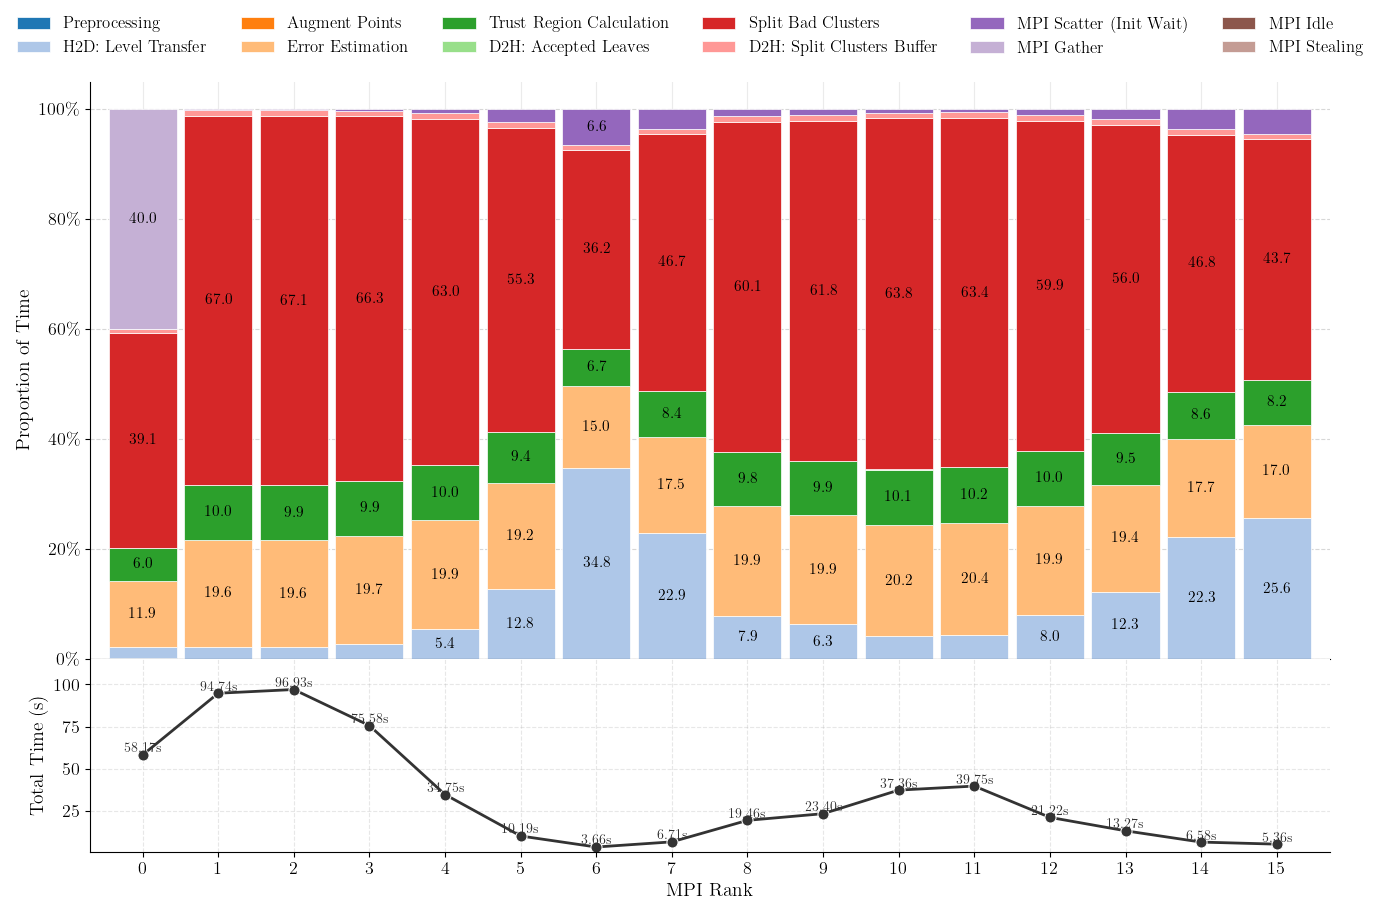

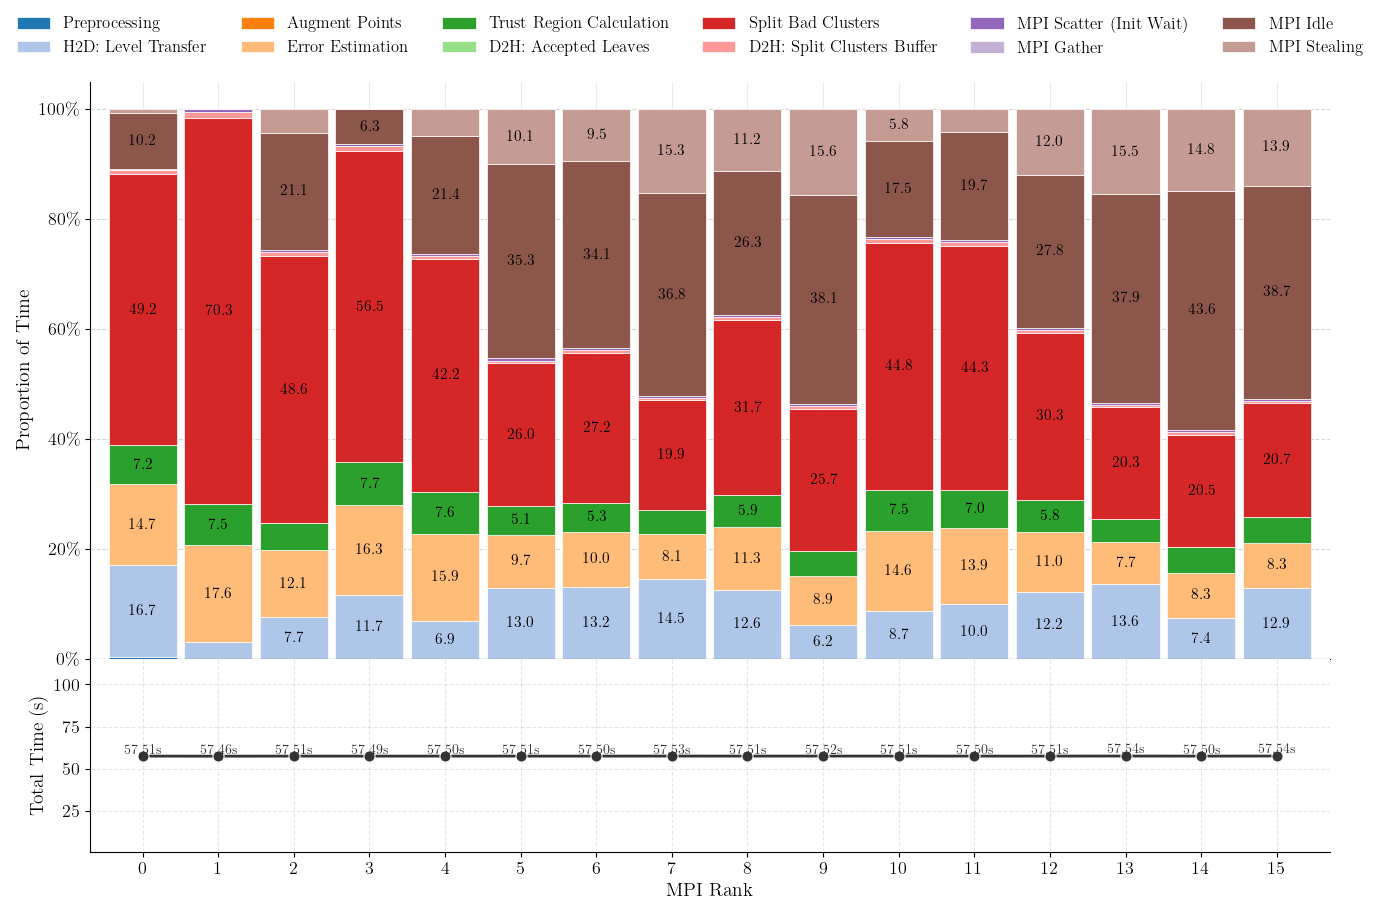

In [ ]:
def plot_mpi_rank_time_breakdown(
    profiling_stats,
    img_fpath: Path,
    top_n_annotate=10,
    min_val_annotate=0.05,
    figsize=(12, 12),
    tick_fontsize=13,
    axis_title_fontsize=14,
    bottom_log_scale=True,
    bottom_ylim=None,
    top_to_bottom_ratio=1.8,
    scale_top_by_runtime=True,
):
    """
    Plot a stacked bar chart of time breakdown per MPI rank,
    with a bottom panel showing total train time per rank.

    Args:
        profiling_stats: Dict containing "per_rank" list of dicts with timing info.
        img_fpath: Path to save the resulting figure.
        top_n_annotate: Number of top segments (by proportion) to annotate per bar.
        min_val_annotate: Minimum proportion threshold for annotation.
        figsize: Figure size.
        tick_fontsize: Font size for tick labels.
        axis_title_fontsize: Font size for axis titles.
        bottom_log_scale: If True, use a log y-axis for the bottom subplot.
        bottom_ylim: Optional y-limits tuple for the bottom subplot.
        top_to_bottom_ratio: Height ratio between the top and bottom subplots.
            1 means equal height, 2 means the top subplot is twice as tall.
        scale_top_by_runtime: If True, top bars are stacked in absolute seconds.
            If False, top bars are normalized to 100% per rank.
    """
    rename_props = {
        "Preprocessing": ["time_init"],
        "H2D: Level Transfer": ["time_transition", "time_slicing", "time_gc"],
        "Augment Points": ["time_find_req_synth", "time_synth_gen"],
        "Error Estimation": ["time_error_calc", "time_filter"],
        "Trust Region Calculation": ["time_good_Q"],
        "D2H: Accepted Leaves": ["time_good_d2h"],
        "Split Bad Clusters": ["time_bad_split"],
        "D2H: Split Clusters Buffer": ["time_bad_d2h"],
        "MPI Scatter (Init Wait)": ["time_scatter"],
        "MPI Gather": ["time_gather"],
        "MPI Idle": ["time_idle"],
        "MPI Stealing": ["time_state_update", "time_mpi_send", "time_mpi_recv"],
    }

    num_ranks = len(profiling_stats["per_rank"])

    # --- Build per-rank DataFrame ---
    rows = []
    for rank in range(num_ranks):
        rank_data = profiling_stats["per_rank"][rank]
        row = {"MPI Rank": rank}
        for category, props in rename_props.items():
            row[category] = sum(rank_data.get(p, 0.0) for p in props)
        # Total time from the raw profiling data
        row["Total Time (s)"] = rank_data.get("time_total", 0.0)
        rows.append(row)

    rank_df = pd.DataFrame(rows)

    # --- DataFrames for stacked bars and annotation ---
    bar_cols = list(rename_props.keys())
    plot_df = rank_df.set_index("MPI Rank")[bar_cols]
    row_sums = plot_df.sum(axis=1)
    plot_df_frac = plot_df.div(row_sums.replace(0.0, np.nan), axis=0).fillna(0.0)
    plot_df_top = plot_df if scale_top_by_runtime else plot_df_frac

    colors = sns.color_palette("tab20", n_colors=len(bar_cols))

    # --- Figure ---
    fig, axs = plt.subplots(
        2,
        1,
        figsize=figsize,
        sharex=True,
        gridspec_kw={"height_ratios": [top_to_bottom_ratio, 1]},
    )
    plt.subplots_adjust(hspace=0, top=0.88)

    # ── TOP: Stacked bars ───────────────────────────────────────────────────
    ax_bar = axs[0]
    plot_df_top.plot(
        kind="bar",
        stacked=True,
        ax=ax_bar,
        color=colors,
        width=0.9,
        edgecolor="white",
        linewidth=0.5,
        legend=False,
    )

    # Annotations use within-rank proportions, regardless of top scaling mode.
    ranks_order = plot_df_frac.rank(axis=1, method="min", ascending=False)
    for col_idx, container in enumerate(ax_bar.containers):
        for row_idx, patch in enumerate(container):
            rank_val = int(ranks_order.iloc[row_idx, col_idx])  # type: ignore
            if rank_val <= top_n_annotate:
                val = float(plot_df_frac.iloc[row_idx, col_idx])  # type: ignore
                if val < min_val_annotate:
                    continue
                x = patch.get_x() + patch.get_width() / 2
                y = patch.get_y() + patch.get_height() / 2
                ax_bar.text(
                    x,
                    y,
                    f"{val * 100:.1f}%",
                    ha="center",
                    va="center",
                    color="black",
                    fontsize=11,
                )

    if scale_top_by_runtime:
        ax_bar.set_ylabel("Time per Rank (s)", fontsize=axis_title_fontsize)
    else:
        ax_bar.set_ylabel("Proportion of Time", fontsize=axis_title_fontsize)
        ax_bar.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))

    ax_bar.grid(axis="y", linestyle="--", alpha=0.5)
    ax_bar.set_xlabel("")
    ax_bar.tick_params(axis="y", labelsize=tick_fontsize)

    # ── BOTTOM: Total time per rank ────────────────────────────────────────
    ax_line = axs[1]
    x_indices = np.arange(num_ranks)
    y_total = rank_df["Total Time (s)"].values

    sns.lineplot(
        x=x_indices,
        y=y_total,
        marker="o",
        ax=ax_line,
        color="#333333",
        linewidth=2,
        markersize=8,
    )
    for x, y in zip(x_indices, y_total):
        ax_line.text(
            x,
            y,
            f"{y:.2f}s",
            ha="center",
            va="bottom",
            fontsize=10,
            color="#333333",
        )

    if bottom_log_scale:
        ax_line.set_yscale("log")
        if bottom_ylim is None:
            ax_line.set_ylim(min(y_total) * 0.3, max(y_total) * 2.5)
        else:
            ax_line.set_ylim(bottom_ylim)
    elif bottom_ylim is not None:
        ax_line.set_ylim(bottom_ylim)

    ax_line.set_ylabel("Total Time (s)", fontsize=axis_title_fontsize)
    ax_line.set_xlabel("MPI Rank", fontsize=axis_title_fontsize)
    ax_line.set_xticks(x_indices)
    ax_line.set_xticklabels([str(r) for r in rank_df["MPI Rank"]])
    ax_line.tick_params(axis="both", labelsize=tick_fontsize)
    ax_line.grid(True, which="both", linestyle="--", alpha=0.3)

    # ── Legend ──────────────────────────────────────────────────────────────
    handles, labels = ax_bar.get_legend_handles_labels()
    fig.legend(
        handles,
        labels,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.96),
        ncol=6,
        frameon=False,
        fontsize=12,
    )

    fig.savefig(img_fpath, bbox_inches="tight")
    plt.show()


bottom_log_scale = False
bottom_ylim = (1, 115)
top_to_bottom_ratio = 3
figsize = (16, 10)
scale_top_by_runtime = False
plot_mpi_rank_time_breakdown(
    profiling_stats=static_data_dict["profiling_stats"].item(),
    img_fpath=RESULTS_DIR / "mpi_rank_time_breakdown_static.png",
    bottom_log_scale=bottom_log_scale,
    bottom_ylim=bottom_ylim,
    top_to_bottom_ratio=top_to_bottom_ratio,
    figsize=figsize,
    scale_top_by_runtime=scale_top_by_runtime,
)
plot_mpi_rank_time_breakdown(
    profiling_stats=dynamic_data_dict["profiling_stats"].item(),
    img_fpath=RESULTS_DIR / "mpi_rank_time_breakdown_dynamic.png",
    bottom_log_scale=bottom_log_scale,
    bottom_ylim=bottom_ylim,
    top_to_bottom_ratio=top_to_bottom_ratio,
    figsize=figsize,
    scale_top_by_runtime=scale_top_by_runtime,
)